# Translate MDL files to python 

@Author: Georgia 
@Last Date: 2024-05/06


This notebook is designed to translate MDL files to Python. The goal is to create a script that can automatically convert Causal Loop Diagrams into Adjacency Matrixs which can then be used for network anlaysis.

A causal loop diagram (CLD) is a visual representation of the causal relationships between variables in a system. It is commonly used in system dynamics modeling to understand the feedback loops and dynamics of a complex system.

To achieve this, we will need to extract the necessary information from the MDL file, including the variables, their relationships, and the polarity of the relationships. We can then use this information to construct an adjacency matrix and a polarity matrix, which can be further analyzed using network analysis techniques.

In this example, I will show a basic exmple of an rabbit population CLD, and the translation to the matrixs. There is one reinforcing loop and one balancing loop in this CLD. Note there is a link between food and rabbit population without a defined polarity.
![Example Image](Testing/rabbit_cld.png)

We will turn this CLD into 3 three objects: 
1. Dict_vars: A dictionary of vairiable names and their index. 
2. Adj_matrix: An adjacency matrix that represents the connections between variables
3. Pol_matrix: A polarity matrix that represents the polarity of the connections



In [1]:
%load_ext autoreload
%autoreload 2

# Import library

In [74]:
import pandas as pd
import numpy as np
import regex as re
import networkx as nx
import itertools as it
import matplotlib.pyplot as plt
import pickle
import sys
import os 


In [8]:
# Add the src directory to the sys.path
sys.path.append(os.path.abspath(os.path.join('..', 'src')))

import parse_cld, cld_nx



# Read txt file of MDL file

In [10]:
# Set the new directory
new_dir = "/Users/gl665/PycharmProjects/Phrame_MentalMaps"
# Change the current working directory
os.chdir(new_dir)

print(os.getcwd())

/Users/gl665/PycharmProjects/Phrame_MentalMaps


In [68]:
# with open('Testing/rabbit_example.mdl', 'r') as f:
#     lines = f.readlines()
with open('Dataset/SYNCH/RC/Passages Clean.mdl', 'r') as f:
    lines = f.readlines()



In [70]:

# # Compile regex to match line with sketch info
start_pattern = re.compile(r".*\*View 1.*")
view2_pattern = re.compile(r".*\*View 2.*")
end_pattern = view2_pattern if any(view2_pattern.match(line) for line in lines) else re.compile(r'/{3}-+\\{3}')
extracted = []
extract = False

for line in lines:
    if start_pattern.match(line):
        # Start new extraction when "View 1" is found
        extract = True
        extracted = []  # Reset extracted lines for new block
        continue  # Skip to next iteration to avoid appending the start line itself

    if extract:
        if end_pattern.match(line):
            # Stop extracting if end pattern found and break if you only need the first block
            extract = False
            break
        extracted.append(line)  # Append current line to extracted

# check the end_pattern what is the pattern.
if end_pattern == view2_pattern:
    extracted = extracted[1:-2]  # Remove the first and last two lines
else:
    extracted = extracted[1:]
df = pd.DataFrame(extracted)
df = df[0].str.split(',', expand=True)
# change column 0 dytpe to int
df[0] = df[0].astype(int)

df

,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
0,10,1,Alcohol Misuse,755,249,49,11,8,3,0,...,0,0,0,0,0,0,0\n,None,None,None
1,10,2,Intimate Partner Violence,753,449,51,19,8,3,0,...,0,0,0,0,0,0,0\n,None,None,None
2,10,3,"""Negative Partners (Broken Person)""",632,568,57,19,8,3,0,...,0,0,0,0,0,0,0\n,None,None,None
3,10,4,Higher Power,446,699,44,11,8,3,0,...,0,0,0,0,0,0,0\n,None,None,None
4,10,5,"""Passages (Re-Entry Facility)""",190,613,63,19,8,3,0,...,0,0,0,0,0,0,0\n,None,None,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
80,1,81,10,16,0,0,0,0,0,128,...,373)|\n,None,None,None,None,None,None,None,None,None
81,1,82,14,5,1,0,43,0,2,128,...,702)|\n,None,None,None,None,None,None,None,None,None
82,1,83,5,7,0,0,0,0,0,128,...,471)|\n,None,None,None,None,None,None,None,None,None
83,10,84,Alcohol Misuse,253,248,58,11,8,2,0,...,0,128-128-128,0-0-0,|0||128-128-128,0,0,0,0,0,0\n


In [71]:

# Grab dependencies 
df_links = df.loc[df[0]==1,  ]
df_links = df_links[[0,1, 2,3,6]]
df_links = df_links.rename(columns={0: 'variable type', 1: 'index',2: 'from', 3: 'to', 6: 'polarity'})
df_links['polarity'] = df_links['polarity'].astype(int)
df_links['links'] = 1
# In Column 6, it depicts, the polarity sign, 43 is positive, 45 is negative, and other values are unknown.

df_links['polarity_type'] = np.where(df_links['polarity'] == 43, 1,
                                     np.where(df_links['polarity'] == 45, -1, 3))

    
# df_links['polarity_type'] = np.where(df_links['polarity'] == 43, 1, -1)
df_links

,variable type,index,from,to,polarity,links,polarity_type
16,1,17,1,2,43,1,1
17,1,18,2,1,43,1,1
18,1,19,1,13,45,1,-1
19,1,20,2,3,43,1,1
20,1,21,3,2,43,1,1
...,...,...,...,...,...,...,...
79,1,80,16,6,0,1,3
80,1,81,10,16,0,1,3
81,1,82,14,5,43,1,1
82,1,83,5,7,0,1,3


In [7]:
# check datatype of df 
# for cols in df.columns:
#     print(df[cols].dtype)
#     

In [72]:
df_vars = df.loc[df[0]==10,  ]
# Create a dictionary based on  dataframe column 1 and 2
dict_var = df_vars.set_index(1)[2].to_dict()

# turn all the variable names in the value to lowercase 
dict_var = {k: v.lower() for k, v in dict_var.items()}
dict_var

# delete unneccessary " and space sign in the variable names in the dictionary 
dict_var = {k: v.replace('"', '') for k, v in dict_var.items()}
dict_var = {k: v.replace('"', '') for k, v in dict_var.items()}
dict_var

{'1': 'alcohol misuse',
 '2': 'intimate partner violence',
 '3': 'negative partners (broken person)',
 '4': 'higher power',
 '5': 'passages (re-entry facility)',
 '6': 'healing',
 '7': 'supportive people',
 '8': 'accountablility',
 '9': 'coping skills',
 '10': 'drugs',
 '11': 'alcohol exposed pregnancy',
 '12': 'death',
 '13': 'family emotional health',
 '14': 'dire situtations',
 '15': 'jail',
 '16': 'mental health',
 '32': 'intimate partner violence',
 '52': 'higher power',
 '60': 'structure and love',
 '61': 'family and child loss (legal)',
 '73': 'drugs',
 '76': 'alcohol exposed pregnancy',
 '78': 'intimate partner violence',
 '84': 'alcohol misuse'}

In [51]:
df_links

,variable type,index,from,to,polarity,links,polarity_type,from_var,to_var,from_new,to_new
16,1,17,5,14,43,1,1,alcohol misuse,intimate partner violence,5,14
17,1,18,14,5,43,1,1,intimate partner violence,alcohol misuse,14,5
18,1,19,5,15,45,1,-1,alcohol misuse,family emotional health,5,15
19,1,20,14,17,43,1,1,intimate partner violence,negative partners (broken person),14,17
20,1,21,17,14,43,1,1,negative partners (broken person),intimate partner violence,17,14
...,...,...,...,...,...,...,...,...,...,...,...
79,1,80,12,11,0,1,3,mental health,healing,12,11
80,1,81,8,12,0,1,3,drugs,mental health,8,12
81,1,82,2,13,43,1,1,dire situtations,passages (re-entry facility),2,13
82,1,83,13,9,0,1,3,passages (re-entry facility),supportive people,13,9


In [67]:

unique_var_values = sorted(set(dict_var.values()))
# sort the set values 
# unique_var_values = sorted(unique_var_values)
# create a dictionary starting from 1, the keys is the number the value is the variable name 
dict_var_final= {k: v for k, v in enumerate(unique_var_values, 1)}
dict_var_final #TODO!!!!!! THIS IS THE CORRECT DICTIONARY 
print(dict_var_final)
# map the dict_var_final using the variable names and create a new column by flipping the dictionary 

# flip a dictionary 

df_links['from_var'] = df_links['from'].map(dict_var)
df_links['to_var'] = df_links['to'].map(dict_var)

df_links['from'] = df_links['from_var'].map( {v: k for k, v in dict_var_final.items()})
df_links['to'] = df_links['to_var'].map( {v: k for k, v in dict_var_final.items()})

{1: 'accountablility', 2: 'alcohol exposed pregnancy', 3: 'alcohol misuse', 4: 'coping skills', 5: 'death', 6: 'dire situtations', 7: 'drugs', 8: 'family and child loss (legal)', 9: 'family emotional health', 10: 'healing', 11: 'higher power', 12: 'intimate partner violence', 13: 'jail', 14: 'mental health', 15: 'negative partners (broken person)', 16: 'passages (re-entry facility)', 17: 'structure and love', 18: 'supportive people'}


# Adjacency matrix: 

link_matrix[2: rabbit population] = 1 means that there is an arrow goes from birth to rabbit population. 

In [52]:
# Make an adjacency matrix and polarity matrix from df_links column from, to and links 
link_matrix = df_links.pivot(index='from', columns='to', values='links').fillna(0).astype(int)

In [53]:
link_matrix

to,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
from,,,,,,,,,,,,,,,,,,
2,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0
3,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
5,0,1,0,1,0,0,0,1,1,1,0,1,0,1,1,1,0,0
7,1,0,0,0,0,0,0,0,0,0,1,1,1,0,0,0,0,1
8,0,0,0,1,1,0,0,0,0,0,0,1,0,1,0,0,0,1
9,0,0,0,0,0,0,1,0,0,0,1,1,0,0,0,0,0,0
10,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,1,0,0
11,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,1


In [54]:
# get the number that exsits in link_matrix.index but does not exsist in link_matrix.columns
missing_cols = set(link_matrix.index) - set(link_matrix.columns)
missing_rows = set(link_matrix.columns) - set(link_matrix.index)

if len(missing_cols) > 0:
    for col in missing_cols:
        link_matrix[col] = 0
if len(missing_rows)> 0: 
    for row in missing_rows:
        link_matrix.loc[row] = 0

# Sort rows and cols by the index of dict_var
link_matrix = link_matrix.sort_index(axis=1)
link_matrix = link_matrix.sort_index(axis = 0)
# link_matrix

In [56]:
link_matrix.columns = link_matrix.columns.map(dict_var_final)
link_matrix

to,coping skills,dire situtations,structure and love,jail,alcohol misuse,death,accountablility,drugs,supportive people,alcohol exposed pregnancy,healing,mental health,passages (re-entry facility),intimate partner violence,family emotional health,family and child loss (legal),negative partners (broken person),higher power
from,,,,,,,,,,,,,,,,,,
1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0
3,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
5,0,1,0,1,0,0,0,1,1,1,0,1,0,1,1,1,0,0
6,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
7,1,0,0,0,0,0,0,0,0,0,1,1,1,0,0,0,0,1
8,0,0,0,1,1,0,0,0,0,0,0,1,0,1,0,0,0,1
9,0,0,0,0,0,0,1,0,0,0,1,1,0,0,0,0,0,0


# Polarity matrix: 

link_matrix[2: rabbit population] = 1 means that there is an positive sign goes from birth to rabbit population
link_matrix[2: rabbit population] = 1 means that there is an positive sign goes from birth to rabbit population. 
. 

In [58]:
polarity_matrix = df_links.pivot(index='from', columns = 'to', values = 'polarity_type').fillna(0).astype(int)


In [59]:
# get the number that exsits in link_matrix.index but does not exsist in link_matrix.columns
missing_cols = set(polarity_matrix.index) - set(polarity_matrix.columns)
missing_rows = set(polarity_matrix.columns) - set(polarity_matrix.index)

if len(missing_cols) > 0:
    for col in missing_cols:
        polarity_matrix[col] = 0
if len(missing_rows)> 0: 
    for row in missing_rows:
        polarity_matrix.loc[row] = 0

# Sort rows and cols by the index of dict_var
polarity_matrix = polarity_matrix.sort_index(axis=1)
polarity_matrix = polarity_matrix.sort_index(axis = 0)
polarity_matrix

to,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
from,,,,,,,,,,,,,,,,,,
1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0
3,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
5,0,1,0,3,0,0,0,1,-1,1,0,-1,0,1,-1,1,0,0
6,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
7,1,0,0,0,0,0,0,0,0,0,1,1,1,0,0,0,0,1
8,0,0,0,1,1,0,0,0,0,0,0,3,0,1,0,0,0,3
9,0,0,0,0,0,0,1,0,0,0,1,1,0,0,0,0,0,0


In [60]:
polarity_matrix.columns = polarity_matrix.columns.map(dict_var_final)
polarity_matrix.index = polarity_matrix.index.map(dict_var_final)

polarity_matrix


to,coping skills,dire situtations,structure and love,jail,alcohol misuse,death,accountablility,drugs,supportive people,alcohol exposed pregnancy,healing,mental health,passages (re-entry facility),intimate partner violence,family emotional health,family and child loss (legal),negative partners (broken person),higher power
from,,,,,,,,,,,,,,,,,,
coping skills,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
dire situtations,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0
structure and love,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0
jail,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
alcohol misuse,0,1,0,3,0,0,0,1,-1,1,0,-1,0,1,-1,1,0,0
death,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
accountablility,1,0,0,0,0,0,0,0,0,0,1,1,1,0,0,0,0,1
drugs,0,0,0,1,1,0,0,0,0,0,0,3,0,1,0,0,0,3
supportive people,0,0,0,0,0,0,1,0,0,0,1,1,0,0,0,0,0,0


In [28]:
# polarity_matrix.to_csv("org passage_mx.csv")

# NetworkX representation

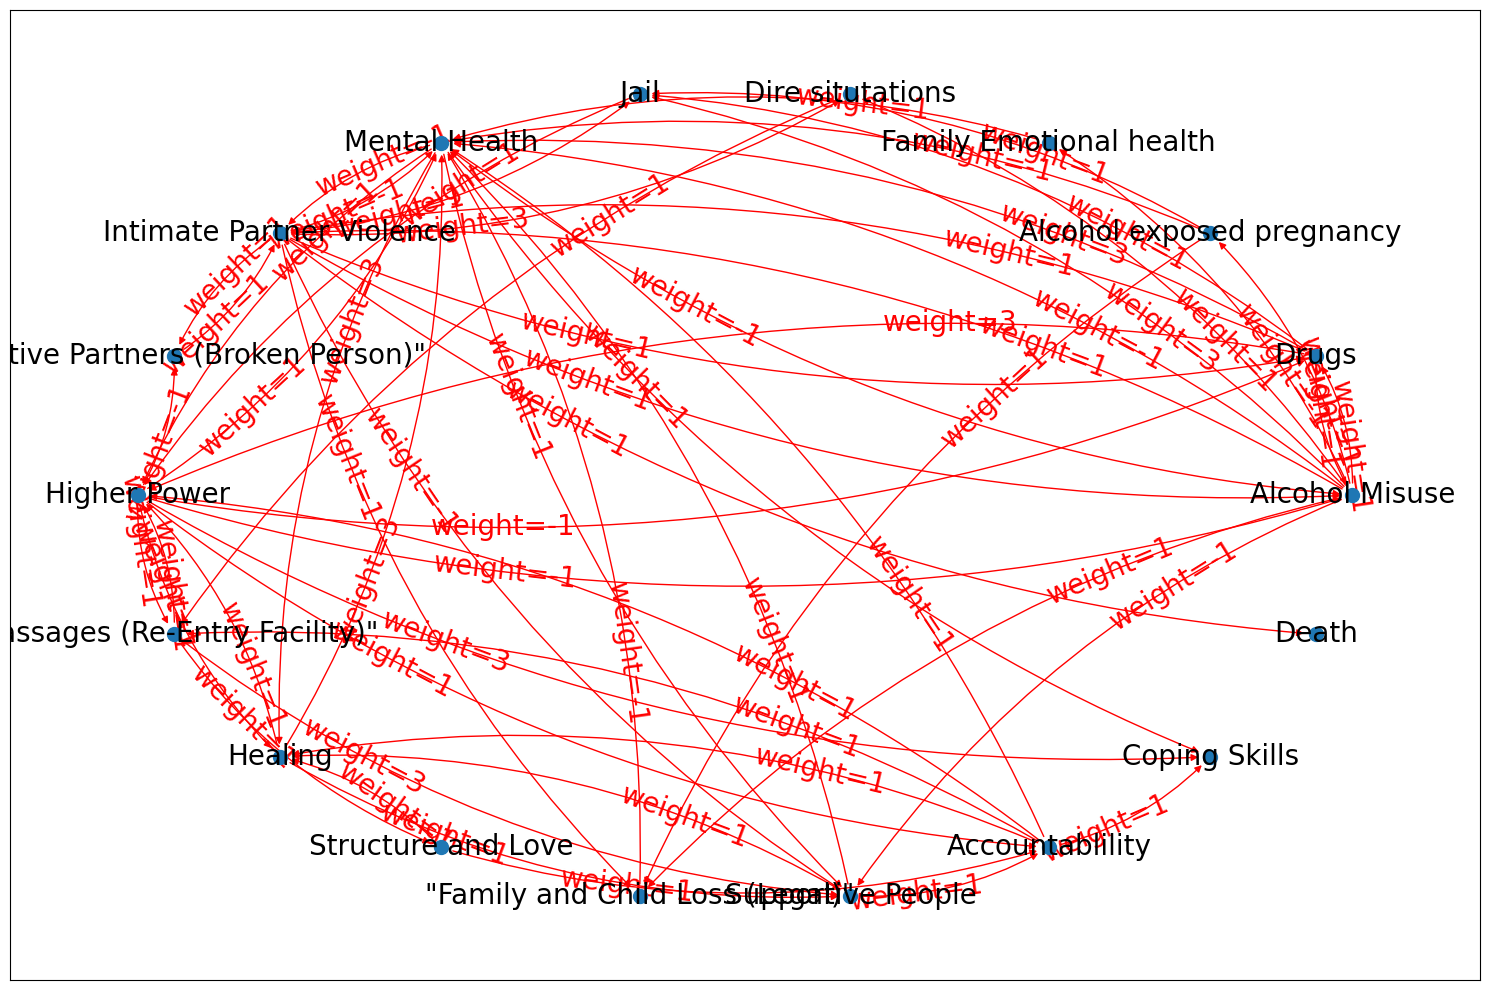

In [29]:
df_subset = df_links[['from', 'to', 'polarity_type']]
# Change the column name polarity type of weight 
df_subset = df_subset.rename(columns={'polarity_type': 'weight'})

d = parse_cld.get_dict_of_dicts(df_subset)
# print(d)
G_test = nx.MultiDiGraph(d)
# print(dict_var)
cld_nx.draw_labeled_multigraph(G_test, "weight", dict_var)
# plt.savefig("Testing/rabbit_example_graph.png")
# plt.show()

In [31]:
import json
with open('Output/Overcome/RC_Models/Overcome RC1 4-5-2023.json', 'rb') as f:
    data = pickle.load(f)

print(data)

[{'1': 'Fatal Overdoses', '2': 'Stimulant Use', '4': 'capital punishment for narcotics', '6': 'Announcement of declaration', '8': 'Ignoring declaration', '10': 'higher rates for AIAN', '11': 'knowledge of what is actually going on', '14': 'Need to enforce punishment', '15': 'Use ISO', '16': 'Disgusing as fentanyl to cause deaths', '22': "Think it's meth but actually ISO", '25': 'Need to control population', '26': 'condemnation of mankind', '29': 'Drug smuggling ISO', '30': 'shutting down of labs', '33': 'local production'}, {'1': {'10': {'weight': 3}}, '11': {'10': {'weight': 3}}, '14': {'15': {'weight': 3}}, '15': {'16': {'weight': 3}, '2': {'weight': 3}, '22': {'weight': 3}}, '16': {'1': {'weight': 3}}, '2': {'1': {'weight': 3}}, '22': {'2': {'weight': 3}, '1': {'weight': 3}}, '25': {'6': {'weight': 3}}, '26': {'25': {'weight': 3}}, '29': {'30': {'weight': 3}}, '30': {'22': {'weight': 3}}, '33': {'2': {'weight': 3}, '1': {'weight': 3}}, '4': {'1': {'weight': 3}, '14': {'weight': 3}},

## Running parse cld functions

In [75]:

from src.parse_cld import read_cld_file, get_cld_df, get_dict_to_vars, get_adjacency_matrix, get_polarity_matrix, get_cld
from src.cld_nx import draw_labeled_multigraph

In [92]:
# with open('Testing/rabbit_example.mdl', 'r') as f:
#     lines = f.readlines()
# with open('Dataset/SYNCH/RC/Passages Clean.mdl', 'r') as f:
#     lines = f.readlines()
input_file = "Dataset/SYNCH/RC/Passages Clean.mdl"
# input_file = "Dataset/SYNCH/Pine_Ridge/C_10_4_2021_2.mdl"
df = read_cld_file(input_file)

dict_vars_name, dict_var = get_dict_to_vars(df)

d = get_cld(df)

# combine the variable names dict and cld data
cld_data = [dict_vars_name, d]
